# 0-instruments: camera-tag

Measure how well the tag pipeline reads an angle from a phone video on the real bench, and its frame to frame noise, so the position experiments in stage 3 know what the camera can and cannot resolve.

## Purpose

Stage 3 measures the servo's horn angle with a phone camera and a printed tag, as the independent reference for the potentiometer. The tag pipeline in `oscnb.fiducial` is tested on rendered frames in `tests/test_fiducial.py`, where the answer is known exactly. A real phone adds lens distortion, focus, lighting, sensor noise and a tag that is not perfectly flat. This experiment puts a number on the angle error and the noise floor under bench conditions, before any servo is involved.

## Procedure

The phone is not scripted. `capture.py` lists the steps, waits for the files, and then runs `equipment/camera/extract.py` over the clips. The extraction calibrates the lens from the board clip and writes a corners table and a real-time preview for each clip. The original clips are not in git. They run to gigabytes (the turn here is 4.4 GB), and the tables hold everything the pipeline takes from them. The originals stay on the host that captured them, identified by the hashes in `manifest.json`. The previews, a few megabytes each at 960 px and 30 fps, are committed so that anyone repeating this can see what was filmed and how.

### Phone settings

Any recent iPhone records what this needs. The settings below are set once, before the first clip, and kept for all three. [equipment/camera/iphone.md](../../../equipment/camera/iphone.md) walks through each one on an iPhone, menu by menu, and covers copying the clips to the host. The lens calibration from `board.mp4` holds only for the setting it was filmed in, and stage 3 films the servo in the same setting.

- **Slow motion, 1080p at 240 fps.** Set it under Settings, Camera, Record Slo-mo, and film in the Camera app's Slo-Mo mode. A servo horn turns at up to about 600 degrees per second. At 30 fps that is about 20 degrees between frames, at 240 fps about 2.5 degrees. Slow motion also keeps the shutter at 1/240 s or shorter, which limits motion blur. 1080p is enough for the angle, since a 25 mm tag filmed from about 20 cm spans a couple of hundred pixels and its edges are fitted to a fraction of a pixel. 4K adds four times the data for no gain in angle that this experiment could use.
- **HDR video off,** under Settings, Camera, Record Video.
- **The 1x lens, with no automatic lens switching.** Pro models switch to the ultrawide lens at close range, which would change the lens in the middle of a clip. Turn on Settings, Camera, Macro Control and switch macro off in the Camera app, or keep the phone more than about 20 cm from the tags.
- **Focus and exposure locked.** Long-press on the tags in the Camera app until AE/AF Lock shows. Exposure that follows the scene changes the tag's edges from clip to clip.
- **Phone fixed, lens pointing straight down,** at the working distance below. Most tripods cannot point straight down this close to the desk. An overhead phone arm clamped to the desk edge works, and so does the phone bridged across two stacks of books with the lens over the gap.
- **Original files.** Set Settings, Photos, Transfer to Mac or PC to Keep Originals, and copy the clips over USB. Sharing through other apps can re-encode a slow motion clip and change its timing. The originals are `.MOV` files. Renaming one to the name below is enough, with no conversion.

A Bluetooth shutter button or an Apple Watch can start and stop recording without touching the phone. Nothing here needs the recording to start at a known moment.

### Working distance

The distance from the lens to the tags is set first, because focus, the lens calibration and the tag's size in pixels all follow from it. About 20 cm, measured with a ruler from the lens to the tag plate, and recorded in `calipers.json`.

- At 1x the frame is about 28 cm wide from 20 cm away, about 6.9 pixels per millimetre at 1080p, so a 25 mm tag spans about 170 pixels. Closer gives more pixels and a lower noise floor. Farther gives fewer.
- The two tags, 60 mm apart in stage 0 and the horn tag sweeping around the reference tag in stage 3, fit near the centre of the frame, where the lens bends least.
- Pro models switch to the macro lens below about 20 cm. Non-Pro models focus closer, but 20 cm is clear of the switch on both.
- In stage 3 the horn tag sits a centimetre or two above the reference tag on the body. At 20 cm both planes stay sharp.

The lens calibration belongs to this distance. Refocusing moves the lens elements and changes the focal length slightly (focus breathing), so the board clip and the tag clips are filmed with the same lock, at the same distance, and the lock is not touched between them. Within about a third of the distance either way the calibration should hold. A setup that changes the distance by more than that, say from 20 cm to 50 cm, gets a new board clip.

### Steps

1. Generate the sheets with `uv run python equipment/camera/tags.py` and print `equipment/camera/tags-angle.pdf` and `tags-calibration.pdf` at actual size, as [equipment/camera/tags.md](../../../equipment/camera/tags.md) describes. Measure each tag's 50 mm check square along X and Y with calipers, and five squares of the board along X and Y, and write the numbers and the phone's video setting into `calipers.json`.
2. Glue the HORN tag and the REFERENCE tag flat on one rigid plate, about 60 mm apart. With both tags on one plate their relative angle is fixed by the print.
3. Fix the phone over the desk, lens straight down, about 20 cm above the plate. Measure the distance from the lens to the tags with a ruler and write it into `calipers.json`. Lock focus and exposure on the tags with the settings above. The phone does not move again until the last clip is done.
4. Film `still.mp4`, the plate at rest under the camera, tags near the frame centre, 10 s.
5. Film `turn.mp4`, turning the plate by hand through one full turn or more in steps, pausing a few seconds at each. The steps need not be equal or counted. The plate's orientation is read from the reference tag.
6. Film `board.mp4`, for the lens calibration, with the phone still on its mount and the lock untouched. Tape the board sheet to a piece of cardboard and move the board under the camera, holding it still for about two seconds at each pose. Flat on the desk in the middle and slid to each corner and each edge of the frame, then propped on a book at 20 to 30 degrees with the raised side facing up, down, left and right in turn, at two or three places each. Fifteen to twenty poses, 30 to 60 s. The extraction takes one frame per pause.

The board clip is filmed with the phone fixed because the phone's stabilisation moves the lens while the phone turns in the hand. A calibration fitted to a moving lens does not describe the lens the tag clips see. The first attempt at this capture was filmed with the phone in the hand and is kept as `board-handheld.mp4`. The Method compares the two. In this capture's `board.mp4` the board, taped to cardboard, was held in the hands at desk height under the fixed phone and held still at each pose, which gave over a hundred pauses. The desk-and-book version above is the easier way to the same clip.

## Data

- `calipers.json`: `phone` (model and video setting), `distance_mm` from the lens to the tags, `horn` and `ref`, each with the measured `x_mm` and `y_mm` of the check square, and `board`, five squares measured along X and Y.
- `camera.json`, the lens calibration from `board.mp4`, written by the extraction.
- `still.corners.csv`, `turn.corners.csv`: one row per frame of the clip, with `frame`, the container time `t` in seconds, the eight refined corner coordinates of each tag in undistorted pixels (`hx0`..`hy3` for the horn tag, `rx0`..`ry3` for the reference), the rms of each tag's edge line fits and its side in pixels. NaN where a tag was not seen.
- `board.preview.mp4`, `board-handheld.preview.mp4`, `still.preview.mp4`, `turn.preview.mp4`: real-time copies, longest side 960 px, for viewing, so the capture can be seen and repeated. Not measured from, except as the stand-in test in the Method, which shows what they cost.
- `manifest.json`: each original clip's size, sha256, frame count and rate, and the pipeline version that made the tables.
- `board.mp4`, `board-handheld.mp4`, `still.mp4`, `turn.mp4`, the originals, gigabytes, not in git. They stay on the host that captured them.

### calipers.json

The hand measurements. The check squares are printed at 50 mm and five board squares at 125 mm. The measured values tell the pipeline the real scale of each print. The distance is recorded so stage 3 can repeat it.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import clips, results, show
import oscnb.fiducial as fd

CAPTURE = Path("../../../telemetry/instruments/camera-tag/capture-1").resolve()

cal = json.loads((CAPTURE / "calipers.json").read_text())
print(json.dumps(cal, indent=2))
horn_scale = fd.PrintScale(**cal["horn"])
ref_scale = fd.PrintScale(**cal["ref"])

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
ROUND = (BLUE, ORANGE)

def dial(ax, title):
    # laid out like the image: y runs down, so angles go clockwise on screen
    ax.set_theta_direction(-1); ax.set_theta_zero_location("E")
    ax.set_xticks(np.radians(np.arange(0, 360, 45)))
    ax.set_xticklabels([str(a) for a in (0, 45, 90, 135, 180, -135, -90, -45)], color=MUTED, fontsize=8)
    ax.set_rlabel_position(90); ax.grid(alpha=0.3); ax.set_title(title, fontsize=10, pad=18)

{
  "phone": "iPhone 17e (MHRN4LL/A, iOS 27.0.1), 1080p 240 fps slo-mo, 1x",
  "distance_mm": 250.0,
  "horn": {
    "x_mm": 50.21,
    "y_mm": 49.77
  },
  "ref": {
    "x_mm": 50.25,
    "y_mm": 49.86
  },
  "board": {
    "x_mm": 125.1,
    "y_mm": 124.25
  },
  "notes": "caliper read -0.76 mm closed; raw readings were 0.76 lower than these. Tags glued with a glue stick on the side of a cardboard box; board sheet taped to cardboard and held in the hands under the fixed phone for board.mp4"
}


### manifest.json

The originals behind the tables, with size, hash, frame count and rate, and the pipeline version. The rate is the container's average. The clips are 240 fps slow motion, and the frame times in the tables come from the container.

In [2]:
manifest = json.loads((CAPTURE / "manifest.json").read_text())
print(json.dumps(manifest, indent=2))

{
  "clips": {
    "board.mp4": {
      "bytes": 1316163452,
      "frames": 24182,
      "fps": 204.46220023885772,
      "width": 1920,
      "height": 1080,
      "duration_s": 118.27125,
      "sha256": "f25daaf19018200c9d45fd0cbead6e0dcd7d7f7a2a3878ed497a85e327d5de0d"
    },
    "board-handheld.mp4": {
      "bytes": 492424524,
      "frames": 9022,
      "fps": 204.09263570640852,
      "width": 1080,
      "height": 1920,
      "duration_s": 44.20541666666667,
      "sha256": "e0483fc88af1183bc990ee4171e11b963ef758f6d1e4593701ad14eea34b2be2"
    },
    "still.mp4": {
      "bytes": 122617699,
      "frames": 2228,
      "fps": 204.30214343025256,
      "width": 1920,
      "height": 1080,
      "duration_s": 10.905416666666666,
      "sha256": "5ffee96802fd7f4b78e9186874ba3da178b2ba8039b08945b0fe7a604ac50bde"
    },
    "turn.mp4": {
      "bytes": 4410341956,
      "frames": 81069,
      "fps": 204.58537323979206,
      "width": 1920,
      "height": 1080,
      "duration_s": 3

### The clips

The first frame of each preview, so the reader sees what the pipeline was given. Frames are BGR from OpenCV and are flipped to RGB for display.

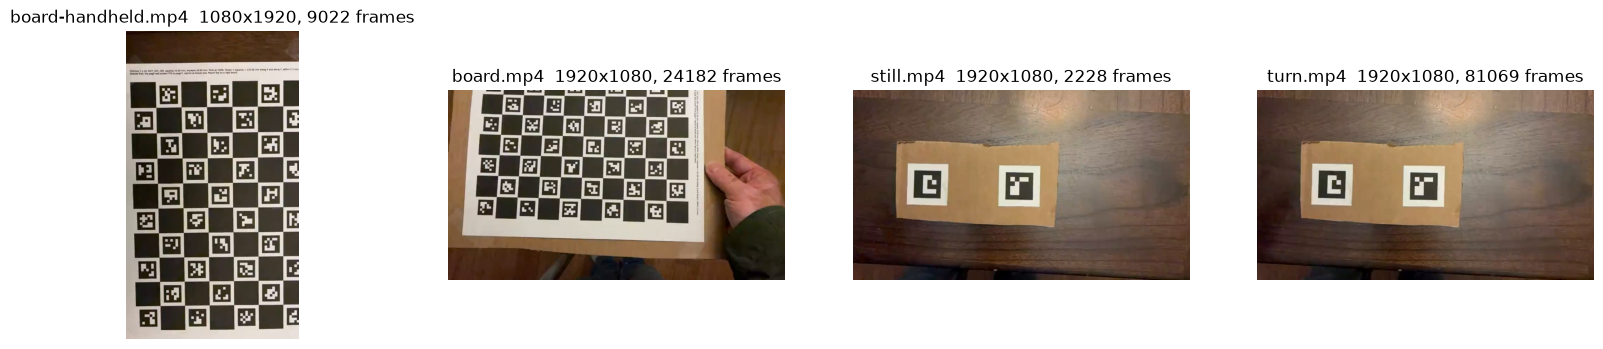

In [3]:
names = ("board-handheld", "board", "still", "turn")
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4))
for ax, name in zip(axes, names):
    _, _, img = next(fd.video_frames(CAPTURE / f"{name}.preview.mp4"))
    m = manifest["clips"][f"{name}.mp4"]
    ax.imshow(img[:, :, ::-1]); ax.set_title(f"{name}.mp4  {m['width']}x{m['height']}, {m['frames']} frames"); ax.axis("off")
plt.show()

Left to right, the phone-in-hand board clip (portrait, with the phone held upright), the board clip from the fixed phone with the board in the hands, the plate at rest, and the plate at the start of the turn.

### The corners tables

The output of the tracking, as the extraction wrote it. The first rows of the still.

In [4]:
still_px = pd.read_csv(CAPTURE / "still.corners.csv")
turn_px = pd.read_csv(CAPTURE / "turn.corners.csv")
show(still_px.head())
for name, df in (("still", still_px), ("turn", turn_px)):
    dt = np.median(np.diff(df.t))
    print(f"{name}: {len(df)} frames, {1 / dt:.0f} fps, horn seen in {int(df.hx0.notna().sum())}, reference in {int(df.rx0.notna().sum())}")

,frame,t,h_line_rms_px,h_side_px,hx0,hy0,hx1,hy1,hx2,hy2,...,r_line_rms_px,r_side_px,rx0,ry0,rx1,ry1,rx2,ry2,rx3,ry3
0,0,0.000,0.108,153.690,351.915,611.539,356.674,456.601,508.322,460.092,...,0.107,155.643,1026.171,625.256,870.225,622.270,873.070,466.968,1029.404,470.390
1,1,0.004,0.106,153.709,351.950,611.337,356.704,456.443,508.379,459.838,...,0.099,155.669,1026.265,625.054,870.243,622.096,873.133,466.744,1029.398,470.143
2,2,0.008,0.105,153.694,351.894,611.164,356.641,456.222,508.356,459.741,...,0.104,155.624,1026.194,624.791,870.204,621.822,873.010,466.435,1029.264,470.052
3,3,0.017,0.097,153.639,351.979,610.807,356.750,455.959,508.408,459.504,...,0.104,155.619,1026.260,624.508,870.306,621.570,873.017,466.219,1029.258,469.694
4,4,0.025,0.098,153.647,351.998,610.772,356.725,455.898,508.436,459.396,...,0.107,155.640,1026.233,624.442,870.276,621.520,873.060,466.119,1029.336,469.639


still: 2228 frames, 238 fps, horn seen in 2228, reference in 2228
turn: 81069 frames, 238 fps, horn seen in 79680, reference in 80227


Each row is one frame. A tag the detector missed, or one with a hand across it, leaves its columns NaN.

## Method

Both tags are on one plate, so the angle of the horn tag measured against the reference tag is a constant fixed by the print. Whatever the pipeline reads for it should come out the same at every orientation of the plate. The spread of that reading over the turn is the pipeline's angle error. The spread over the still clip, where nothing moves, is the noise floor.

The pipeline reads the angle two ways, from the same corners tables. The plane-mapped reading maps the horn tag's corners into the reference tag's plane through the reference's four corners and reads the angle there. It works for a camera at any angle to the plate. The image reading takes the direction each tag's edges point in the undistorted image and subtracts one from the other. It is exact only for planes square to the camera, and off by about half the tilt squared otherwise. Stage 3 films from straight above, so the image reading is the one it will use, and the plane-mapped reading is kept beside it as a check. The corners themselves come from the extraction, with the lens from `camera.json` and each corner refined by the tag's edge lines.

Two frames with the tables drawn over them, so the numbers have a picture. The tracked corners of each tag, and an arrow for the direction its edges point in the image.

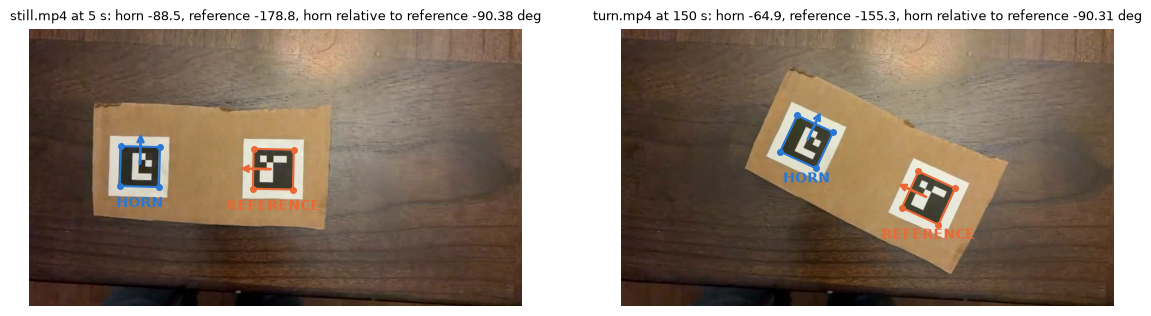

In [5]:
def preview_frame(name, t_want):
    k = int(round(t_want * 30))
    _, t, img = next(fd.video_frames(CAPTURE / f"{name}.preview.mp4", start=k, stop=k + 1))
    return t, img, img.shape[1] / manifest["clips"][f"{name}.mp4"]["width"]

def draw_tags(ax, img, row, scale):
    ax.imshow(img[:, :, ::-1]); ax.axis("off")
    for tag, colour, label in (("h", BLUE, "HORN"), ("r", ORANGE, "REFERENCE")):
        c = fd.corners(row.to_frame().T, tag)[0] * scale
        ax.plot(*np.vstack([c, c[:1]]).T, "-", color=colour, lw=1.5); ax.plot(*c.T, "o", color=colour, ms=4)
        centre, side, a = c.mean(axis=0), np.linalg.norm(c[1] - c[0]), np.radians(fd.edge_direction(c))
        ax.annotate("", xy=centre + 0.9 * side * np.array([np.cos(a), np.sin(a)]), xytext=centre, arrowprops=dict(arrowstyle="->", color=colour, lw=2))
        ax.text(centre[0], centre[1] + 0.75 * side, label, color=colour, ha="center", va="top", fontsize=10, fontweight="bold")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (name, df, t_want) in zip(axes, (("still", still_px, 5.0), ("turn", turn_px, 150.0))):
    t, img, scale = preview_frame(name, t_want)
    row = df.iloc[(df.t - t).abs().argmin()]
    draw_tags(ax, img, row, scale)
    hc, rc = fd.corners(row.to_frame().T, "h")[0], fd.corners(row.to_frame().T, "r")[0]
    ax.set_title(f"{name}.mp4 at {t:.0f} s: horn {fd.edge_direction(hc):+.1f}, reference {fd.edge_direction(rc):+.1f}, horn relative to reference {fd.image_angle(hc, rc):.2f} deg", fontsize=9)
plt.show()

Left, the plate at rest. Right, part way through the turn, with both arrows swung together. The angle the experiment reads is the horn's arrow relative to the reference's. On this plate the print fixes it near 90 degrees, and it should read the same however the plate is turned.

### The lens

Fitted by the extraction from one view per pause of the board clip. Read back here for its fit quality, then compared with a fit from the phone-in-hand clip, made the same way (that clip has no pauses, so every sampled frame is a view). The check on each is whether two halves of its views agree on the focal length.

In [6]:
cam = fd.Camera.load(CAPTURE / "camera.json")
board_scale = clips.board_scale(CAPTURE)
print(f"fixed phone: {cam.views} views, {cam.rms_px:.3f} px rms, f {cam.K[0, 0]:.0f} {cam.K[1, 1]:.0f} px, size {cam.size}")
lens = {"fixed": cam}
for name, path in (("fixed", CAPTURE / "board.mp4"), ("hand-held", CAPTURE / "board-handheld.mp4")):
    views, pauses = clips.board_views(path, board_scale)
    if name == "hand-held":
        lens[name] = fd.calibrate(views, scale=board_scale)
        print(f"phone in hand: {lens[name].views} views from every sampled frame, {lens[name].rms_px:.3f} px rms, f {lens[name].K[0, 0]:.0f} {lens[name].K[1, 1]:.0f} px, size {lens[name].size}")
    half = len(views) // 2
    a, b = fd.calibrate(views[:half], scale=board_scale), fd.calibrate(views[half:], scale=board_scale)
    print(f"  {name}: {pauses} pauses; focal length from the two halves of the views {a.K[0, 0]:.0f} and {b.K[0, 0]:.0f} px, {100 * abs(a.K[0, 0] - b.K[0, 0]) / lens[name].K[0, 0]:.1f} % apart")

fixed phone: 60 views, 0.554 px rms, f 1561 1555 px, size (1920, 1080)


  fixed: 132 pauses; focal length from the two halves of the views 1559 and 1566 px, 0.4 % apart


phone in hand: 60 views from every sampled frame, 1.945 px rms, f 1714 1720 px, size (1080, 1920)


  hand-held: 0 pauses; focal length from the two halves of the views 2623 and 1592 px, 60.2 % apart


The fixed-phone clip fits to about half a pixel, and its two halves agree on the focal length to a fraction of a percent. The phone-in-hand clip fits to two pixels, and its two halves disagree on the focal length by tens of percent. The most likely reason is the phone's stabilisation, which moves the lens while the phone turns in the hand, so there is no single lens to fit. The procedure therefore films the board with the phone on its mount, whatever holds the board.

### The still

The plate at rest. The reference tag's mapping is taken once from its median corners (`static_ref=True`), as stage 3 does with the tag on the servo body, and the frame to frame scatter of the angle is the noise floor.

2228 frames, horn tag 154 px across, relative angle -90.515 deg, noise sd 0.0126 deg, peak to peak 0.114 deg, reference motion median 0.06 px


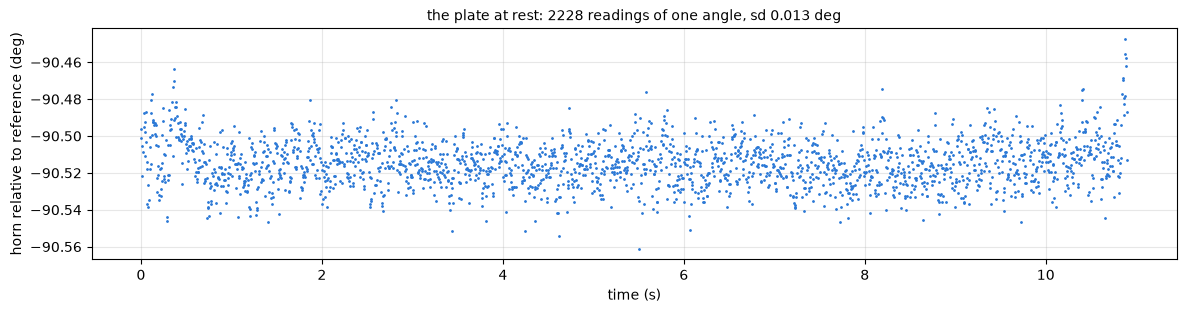

In [7]:
still = fd.angles(still_px, scale=horn_scale, ref_scale=ref_scale, static_ref=True)
noise_deg = float(still.angle_deg.std())
print(f"{len(still)} frames, horn tag {still.h_side_px.median():.0f} px across, relative angle {still.angle_deg.median():.3f} deg, noise sd {noise_deg:.4f} deg, "
      f"peak to peak {still.angle_deg.max() - still.angle_deg.min():.3f} deg, reference motion median {still.ref_motion_px.median():.2f} px")
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(still.t, still.angle_deg, ".", ms=2, color=BLUE)
ax.set_xlabel("time (s)"); ax.set_ylabel("horn relative to reference (deg)"); ax.grid(alpha=0.3)
ax.set_title(f"the plate at rest: {len(still)} readings of one angle, sd {noise_deg:.3f} deg", fontsize=10)
plt.show()

The relative angle frame by frame with the plate at rest. Its standard deviation is the noise floor. The shutter press and release move the phone slightly in the first and last tenth of a second.

### The turn

Both tags move together, so the reference's mapping is recomputed every frame (`static_ref=False`), and both readings of the relative angle should come out constant. The plate's orientation in the image is read from the reference tag's edge directions, and the turn is unwrapped to count the rounds.

79567 frames with both tags, plate turned -630 deg in 396 s


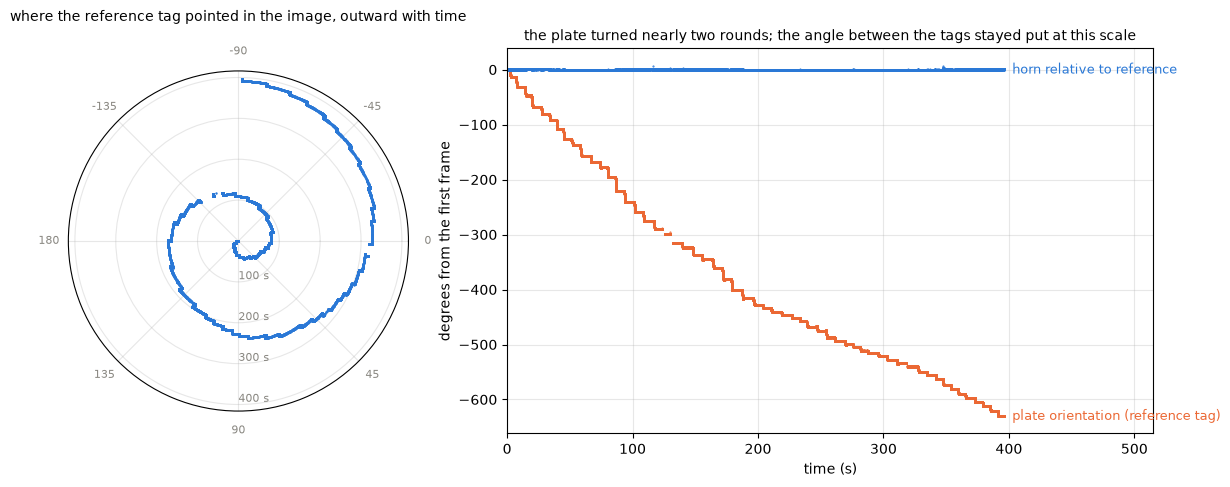

In [8]:
turn = fd.angles(turn_px, scale=horn_scale, ref_scale=ref_scale, static_ref=False, unwrap=False)
turn = turn.dropna(subset=["angle_deg"]).copy()
r, h = fd.corners(turn, "r"), fd.corners(turn, "h")
turn["plate_deg"] = fd.edge_direction(r)
unwrapped = np.degrees(np.unwrap(np.radians(turn.plate_deg)))
turn["turned_deg"] = unwrapped - unwrapped[0]
turn["round"] = (turn.turned_deg.abs() // 360).astype(int)
turn["err_deg"] = (turn.angle_deg - turn.angle_deg.median() + 180) % 360 - 180
turn["image_err_deg"] = (turn.image_deg - turn.image_deg.median() + 180) % 360 - 180
print(f"{len(turn)} frames with both tags, plate turned {turn.turned_deg.iloc[-1]:+.0f} deg in {turn.t.iloc[-1]:.0f} s")
fig = plt.figure(figsize=(14, 5))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.9])
ax = fig.add_subplot(gs[0], projection="polar")
dial(ax, "where the reference tag pointed in the image, outward with time")
ax.plot(np.radians(turn.plate_deg), turn.t, ".", ms=1.5, color=BLUE)
ax.set_rticks([100, 200, 300, 400]); ax.set_yticklabels(["100 s", "200 s", "300 s", "400 s"], color=MUTED, fontsize=8)
ax = fig.add_subplot(gs[1])
ax.plot(turn.t, turn.turned_deg, ".", ms=1, color=ORANGE)
ax.plot(turn.t, turn.angle_deg - turn.angle_deg.median(), ".", ms=1, color=BLUE)
ax.text(turn.t.iloc[-1], turn.turned_deg.iloc[-1], "  plate orientation (reference tag)", color=ORANGE, va="center", fontsize=9)
ax.text(turn.t.iloc[-1], 0, "  horn relative to reference", color=BLUE, va="center", fontsize=9)
ax.set_xlim(0, turn.t.iloc[-1] * 1.3); ax.set_xlabel("time (s)"); ax.set_ylabel("degrees from the first frame"); ax.grid(alpha=0.3)
ax.set_title("the plate turned nearly two rounds; the angle between the tags stayed put at this scale", fontsize=10)
plt.show()

Left, the plate's orientation as a dial. Each frame is a dot at the angle the reference tag pointed in the image, at a radius of its time, so the clip spirals outward through the rounds. Right, the same orientation unwrapped against time, a staircase of hand turns and pauses, with the horn tag's angle relative to the reference under it on the same axis. The plate went round nearly twice. The relative angle stayed where it was at this scale, and the rest of the notebook looks at it more closely.

image reading: error sd 0.117 deg, 90 % of frames within 0.160 deg, 99 % within 0.304, worst 5.90
plane mapped: error sd 0.236 deg, 90 % of frames within 0.369 deg, 99 % within 0.484, worst 6.54
relative angle: image reading -90.187 deg, plane mapped -90.531 deg; the two errors correlate at +0.29


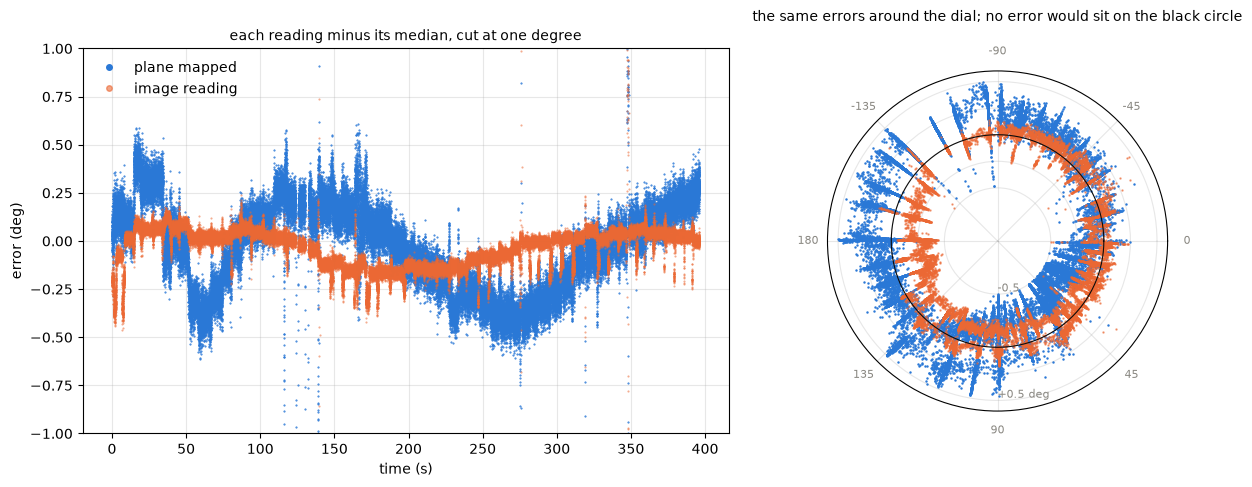

In [9]:
err_90 = float(turn.err_deg.abs().quantile(0.9))
image_90 = float(turn.image_err_deg.abs().quantile(0.9))
for name, e in (("image reading", turn.image_err_deg), ("plane mapped", turn.err_deg)):
    print(f"{name}: error sd {e.std():.3f} deg, 90 % of frames within {e.abs().quantile(0.9):.3f} deg, 99 % within {e.abs().quantile(0.99):.3f}, worst {e.abs().max():.2f}")
print(f"relative angle: image reading {turn.image_deg.median():.3f} deg, plane mapped {turn.angle_deg.median():.3f} deg; the two errors correlate at {np.corrcoef(turn.err_deg, turn.image_err_deg)[0, 1]:+.2f}")
fig = plt.figure(figsize=(14, 5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.9, 1])
ax = fig.add_subplot(gs[0])
ax.plot(turn.t, turn.err_deg, ".", ms=1, color=BLUE, label="plane mapped")
ax.plot(turn.t, turn.image_err_deg, ".", ms=1, color=ORANGE, alpha=0.6, label="image reading")
ax.set_ylim(-1, 1); ax.set_xlabel("time (s)"); ax.set_ylabel("error (deg)"); ax.grid(alpha=0.3); ax.legend(markerscale=8, frameon=False)
ax.set_title("each reading minus its median, cut at one degree", fontsize=10)
ax = fig.add_subplot(gs[1], projection="polar")
dial(ax, "the same errors around the dial; no error would sit on the black circle")
ax.plot(np.radians(turn.plate_deg), 1 + turn.err_deg.where(turn.err_deg.abs() < 0.5), ".", ms=1.5, color=BLUE)
ax.plot(np.radians(turn.plate_deg), 1 + turn.image_err_deg.where(turn.image_err_deg.abs() < 0.5), ".", ms=1.5, color=ORANGE, alpha=0.6)
ax.plot(np.linspace(0, 2 * np.pi, 361), np.ones(361), "-", color=INK, lw=0.8)
ax.set_rlim(0, 1.6); ax.set_rticks([0.5, 0.75, 1, 1.25, 1.5]); ax.set_yticklabels(["-0.5", "", "0", "", "+0.5 deg"], color=MUTED, fontsize=8)
plt.show()

Left, each reading minus its own median along the clip, cut at one degree. The spikes beyond are frames with a hand across a tag. Right, the same errors laid around the dial at the orientation the plate had, with the frames beyond half a degree left out. A reading with no error would trace the black circle. Both readings wander by a few tenths of a degree, the plane-mapped one more. Whether the error depends on the orientation alone is checked below, by comparing the two rounds at the same orientation.

### What the error follows

Three things could move the readings. The lens model, the plate's tilt to the camera, and the plane mapping itself. The plate's tilt is read frame by frame from the reference tag with a pose fit, and each reading's error is binned by it.

plate tilt to the camera axis: median 1.4 deg, 90 % under 2.6, max 5.7


,frames,image_median,image_sd,mapped_median,mapped_sd
tilt_deg,,,,,
"(0, 1]",19627,-0.105,0.072,-0.250,0.176
"(1, 2]",36975,-0.002,0.096,-0.021,0.227
"(2, 3]",20487,0.036,0.138,0.115,0.162
"(3, 10]",2478,-0.052,0.188,0.105,0.230


image reading: round 1 against round 0 at the same orientation, median gap 0.068 deg, worst 0.289
plane mapped: round 1 against round 0 at the same orientation, median gap 0.079 deg, worst 0.453


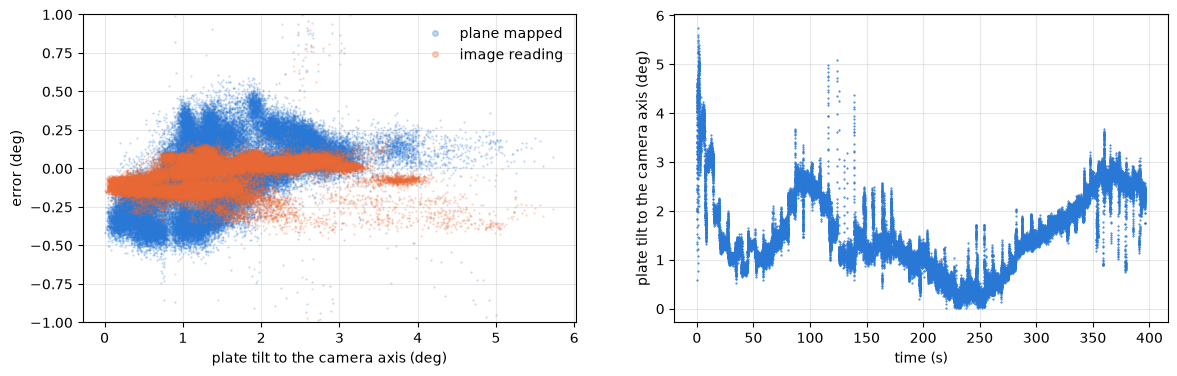

In [10]:
model = np.hstack([fd.tag_model(ref_scale), np.zeros((4, 1))])
tilt = np.full(len(turn), np.nan)
for k in range(0, len(turn), 4):
    ok, rvec, _ = cv2.solvePnP(model, r[k].astype(np.float64), cam.K, None, flags=cv2.SOLVEPNP_ITERATIVE)
    if ok:
        n = cv2.Rodrigues(rvec)[0] @ [0.0, 0.0, 1.0]
        tilt[k] = np.degrees(np.arccos(abs(n[2])))
turn["tilt_deg"] = pd.Series(tilt, index=turn.index).interpolate(limit_direction="both")
tilt_90 = float(turn.tilt_deg.quantile(0.9))
print(f"plate tilt to the camera axis: median {turn.tilt_deg.median():.1f} deg, 90 % under {tilt_90:.1f}, max {turn.tilt_deg.max():.1f}")
bands = pd.cut(turn.tilt_deg, [0, 1, 2, 3, 10])
table = turn.groupby(bands, observed=True).agg(frames=("err_deg", "size"), image_median=("image_err_deg", "median"), image_sd=("image_err_deg", "std"),
                                                mapped_median=("err_deg", "median"), mapped_sd=("err_deg", "std")).round(3)
show(table, n=10)
repeat = {}
for name, col in (("image reading", "image_err_deg"), ("plane mapped", "err_deg")):
    p = turn.groupby([pd.cut(turn.plate_deg, np.arange(-180, 181, 10)), "round"], observed=True)[col].median().unstack("round")
    repeat[col] = (p[1] - p[0]).dropna().abs()
    print(f"{name}: round 1 against round 0 at the same orientation, median gap {repeat[col].median():.3f} deg, worst {repeat[col].max():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(turn.tilt_deg, turn.err_deg, ".", ms=1, color=BLUE, alpha=0.3, label="plane mapped"); ax[0].plot(turn.tilt_deg, turn.image_err_deg, ".", ms=1, color=ORANGE, alpha=0.3, label="image reading")
ax[0].set_ylim(-1, 1); ax[0].set_xlabel("plate tilt to the camera axis (deg)"); ax[0].set_ylabel("error (deg)"); ax[0].legend(markerscale=8, frameon=False); ax[0].grid(alpha=0.3)
ax[1].plot(turn.t, turn.tilt_deg, ".", ms=1, color=BLUE); ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("plate tilt to the camera axis (deg)"); ax[1].grid(alpha=0.3)
plt.show()

Left, each reading's error against the plate's tilt. Right, the tilt along the clip, which changes as the hand lifts an edge while turning. The table gives each reading's offset and spread by tilt band. The plane-mapped reading shifts by about 0.4 degrees between the flattest frames and the ones tilted 2 to 3 degrees, the image reading by about 0.15, and within a band the image reading's spread is about half. The printed gap between the two rounds at the same orientation is of the same size as the error itself, so the error is not a function of the orientation alone.

A separate check, not in this notebook because it re-tracks the clip. Every 20th frame of the turn was tracked again with the lens distortion set to zero. The plane-mapped error changed from 0.240 to 0.245 degrees sd, and the two errors correlate at 0.96. So the lens model is not what moves the reading, with good confidence.

### The previews as a stand-in

The originals are not in git, but the previews are, so the whole pipeline can be tried on them. The previews are copied to a temporary folder under the originals' names and extracted as if they were the capture, calibration included. They are 960 px wide and 30 fps, so the tags are half the size in pixels, there are eight times fewer frames, and the compression has worked on the edges. This cell shows what that costs, next to the real run.

In [11]:
import shutil
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    for name in ("board", "still", "turn"):
        shutil.copy(CAPTURE / f"{name}.preview.mp4", tmp / f"{name}.mp4")
    shutil.copy(CAPTURE / "calipers.json", tmp / "calipers.json")
    clips.extract(tmp, log=lambda *a: None, previews=False)
    pv_cam = fd.Camera.load(tmp / "camera.json")
    pv_still = fd.angles(pd.read_csv(tmp / "still.corners.csv"), scale=horn_scale, ref_scale=ref_scale, static_ref=True)
    pv_turn = fd.angles(pd.read_csv(tmp / "turn.corners.csv"), scale=horn_scale, ref_scale=ref_scale, static_ref=False, unwrap=False).dropna(subset=["angle_deg"])
pv_err = (pv_turn.angle_deg - pv_turn.angle_deg.median() + 180) % 360 - 180
pv_image = (pv_turn.image_deg - pv_turn.image_deg.median() + 180) % 360 - 180
show(pd.DataFrame({
    "originals": [cam.views, round(cam.rms_px, 2), round(float(still.h_side_px.median())), len(turn), round(noise_deg, 4), round(err_90, 3), round(image_90, 3)],
    "previews": [pv_cam.views, round(pv_cam.rms_px, 2), round(float(pv_still.h_side_px.median())), len(pv_turn), round(float(pv_still.angle_deg.std()), 4),
                 round(float(pv_err.abs().quantile(0.9)), 3), round(float(np.quantile(np.abs(pv_image), 0.9)), 3)],
}, index=["lens views", "lens rms (px)", "tag (px)", "turn frames", "noise sd (deg)", "mapped error 90 % (deg)", "image error 90 % (deg)"]), n=10)

,originals,previews
lens views,60.000,60.000
lens rms (px),0.550,0.330
tag (px),154.000,77.000
turn frames,79567.000,11681.000
noise sd (deg),0.013,0.060
mapped error 90 % (deg),0.369,0.711
image error 90 % (deg),0.160,0.159


The previews work as a stand-in for trying the pipeline, with worse numbers. The noise floor is several times higher with half the pixels per tag and compressed edges, and the plane-mapped error grows with it. The image reading hardly changes, which fits its error being set by geometry rather than pixels. Anyone repeating this with their own originals should see numbers nearer the originals column than the previews column.

## Results

The spread over the turn for both readings, the noise floor of the still, and the lens fit quality and tag size for context. The image reading is the reading of record for stage 3, which films from straight above, and goes in as `angle_error_deg`. The plane-mapped reading is recorded beside it as `angle_error_mapped_deg`, the cross-check.

In [12]:
results.write("0-instruments", "camera-tag", CAPTURE,
              notes=f'{cal["phone"]}, {cal["distance_mm"]:.0f} mm lens to tags; errors are the 90th percentile of |error| over the turn with both tags moving; angle_error_deg is the image reading, for a camera square to the tags, and angle_error_mapped_deg the plane-mapped cross-check',
              angle_error_deg=results.quantity(image_90, unit="deg"),
              angle_error_mapped_deg=results.quantity(err_90, unit="deg"),
              noise_deg=results.quantity(noise_deg, unit="deg"),
              plate_tilt_90_deg=results.quantity(tilt_90, unit="deg"),
              lens_rms_px=results.quantity(cam.rms_px, unit="px"),
              tag_px=results.quantity(still.h_side_px.median(), unit="px"))

PosixPath('stages/0-instruments/camera-tag/results.json')

## Limitations

- The turn moves both tags, so the reference's mapping is recomputed every frame from four corners. Stage 3 keeps the reference tag fixed on the body and averages its mapping over the whole clip, an easier case that the still clip represents.
- The plate is cardboard, turned and lifted by hand. Its flatness and its tilt are not controlled. That is realistic for a bench, but it mixes two effects in one clip.
- The result holds for this phone, this video setting, this working distance and so this tag size in pixels. A different distance or resolution changes the tag's pixel size and with it the noise floor, and a distance change of more than about a third needs a new lens calibration.
- Every frame of the turn is a slow hand turn or a pause. Nothing here says how either reading behaves on a horn moving at hundreds of degrees per second, where the edges blur over the shutter time.
- The board clip left the bottom quarter and the right edge of the frame thin. The tags stayed near the centre, so this capture does not depend on them.
- The board was held in the hands for that clip. Its flatness is not controlled beyond what the fit shows, 0.55 px rms.

## Open questions

- Are the two tags coplanar? A rigid plate (a tile, with the tags glued and measured for flatness) and the same turn would separate a bowed plate from the mapping's own sensitivity. If the error falls with the rigid plate, the hypothesis below holds.
- A larger reference, or a reference with more corners (a small ChArUco patch instead of one tag), pins the plane from more than four points. The same turn with such a reference would measure how much of the error is the four-corner mapping.
- Speed. A turn by a motor at a known rate, or the servo itself in stage 3 with the pot as the second witness, would show what motion blur does to each reading.
- Light. Repeat the still in dim light to see how the noise floor moves with sensor noise.
- Extraction speed. The full-frame tag search and the per-frame refinement run at about 100 frames per second on the host. Searching only near the previous frame's tags would make the extraction several times faster. Not needed yet.

## Conclusion

The noise floor is 0.013 degrees per frame (one standard deviation) with the tags 154 pixels across, from 25 cm at 1080p and 240 fps, with the reference's mapping held fixed as stage 3 holds it. Frame to frame, the pipeline resolves about a hundredth of a degree on this setup.

The systematic error is larger. Over one and three quarter turns with both tags moving, the image reading from the tags' edge directions stayed within 0.16 degrees for 90 % of frames (sd 0.12), and the plane-mapped reading within 0.37 degrees (sd 0.24). Both errors follow the plate's tilt to the camera axis, which ran 1 to 3 degrees here as the hand lifted an edge while turning. They do not follow the lens. Re-tracking with the distortion set to zero left them unchanged. For the plane-mapped reading the hypothesis, with medium confidence, is that the mapping from the reference tag's four corners is what the tilt acts on. That could be because the two tags are not quite coplanar on the cardboard (an error first order in the tilt times the bow), because the four-corner mapping amplifies corner errors under tilt, or because a small error in the camera model's centre or focal length enters the mapping. Which of the three it is stays open, and the open questions name the measurements that would separate them. The image reading has no mapping. Its smaller tilt error is consistent with the half tilt squared term plus the same non-coplanar tags, but this capture does not separate those either.

For stage 3, against its 0.1 degree target, the noise is not the limit. The image reading is the reading of record, since stage 3 films from straight above, and the plane-mapped reading stays in the table as the cross-check. A gap between the two on a stage 3 run is a sign of tilt. In this capture's flattest frames the image reading spread 0.07 degrees (sd) and the plane-mapped one 0.18. So the target looks reachable with the camera square to the horn within a degree, checked with the phone's level and the body tag's measured tilt, and with the body tag's mapping fixed over the clip as the still did. Reachable is the word, not shown. The 0.16 degrees from the whole turn is the number to carry until a stage 3 run under its own conditions says otherwise. The horn's plate in stage 3 can tilt as the horn turns, which this plate did not do, and fast motion is untested.

The procedure changed during this capture. The board clip is filmed with the phone on its mount and the board moved under it, pausing at each pose. A board clip filmed with the phone in the hand did not calibrate this phone. The board in the hand under a fixed phone was fine.